# CS 521 HW4, Problem 3: PPO on CartPole

Open this notebook in Google Colab. The CPU runtime is sufficient: a GPU does not make this notebook faster.

The notebook has a complete implementation of PPO for the CartPole-v1 environment.
In part (a) of Problem 3, you run it and examine two of its parts.
In Bonus Research Question 2, you change the algorithm to improve learning.
Do not change the environment, the training budget (`total_steps`) or the evaluation.

**Environment.** CartPole-v1 gives a reward of +1 for each step. An episode ends when the pole falls
(*termination*) or after 500 steps (*truncation*, a time limit). Thus the maximum return is 500.

In [1]:
# !pip install gymnasium   # Colab has gymnasium. Remove the comment if the import fails.
import copy
import time

import gymnasium as gym
import numpy as np
import torch
import torch.nn as nn
from torch.distributions import Categorical

torch.set_num_threads(1)

CONFIG = dict(
    total_steps=200_000,   # training budget (environment steps). Do not change.
    num_envs=4,            # parallel environments
    num_steps=128,         # steps per environment for each rollout
    lr=2.5e-4,
    anneal_lr=True,        # decrease the learning rate linearly to 0
    gamma=0.99,
    gae_lambda=0.95,
    num_minibatches=4,
    update_epochs=4,
    clip_coef=0.2,
    ent_coef=0.01,
    vf_coef=0.5,
    max_grad_norm=0.5,
    norm_adv=True,         # normalize the advantages in each minibatch
)
SEEDS = [0, 1, 2, 3, 4]

# Environments

`Envs` runs `num_envs` copies of CartPole. When an episode ends, `step` resets that copy automatically.
For each copy, `step` returns:

* `obs`: the next observation. If the episode ended, this is the first observation of the new episode.
* `reward`, `terminated`, `truncated`.
* `final_obs`: the last observation of the episode that ended (`None` if the episode did not end).

`step` also records the return of each finished episode in `self.episodes` as `(global_step, return)`.

In [2]:
class Envs:
    def __init__(self, n, seed):
        self.envs = [gym.make("CartPole-v1") for _ in range(n)]
        self.obs = np.stack([e.reset(seed=seed + i)[0] for i, e in enumerate(self.envs)])
        for i, e in enumerate(self.envs):
            e.action_space.seed(seed + i)
        self.ep_return = np.zeros(n)
        self.global_step = 0
        self.episodes = []

    def step(self, actions):
        rewards, terms, truncs, final_obs = [], [], [], []
        for i, (e, a) in enumerate(zip(self.envs, actions)):
            o, r, term, trunc, _ = e.step(int(a))
            self.ep_return[i] += r
            fo = None
            if term or trunc:
                fo = o
                self.episodes.append((self.global_step + i + 1, self.ep_return[i]))
                self.ep_return[i] = 0
                o, _ = e.reset()
            self.obs[i] = o
            rewards.append(r); terms.append(term); truncs.append(trunc); final_obs.append(fo)
        self.global_step += len(self.envs)
        return self.obs.copy(), np.array(rewards), np.array(terms), np.array(truncs), final_obs

# Agent

The agent has two separate networks with 2 hidden layers of 64 neurons: the actor (policy) and the critic (value).

In [3]:
def layer_init(layer, std=np.sqrt(2), bias=0.0):
    nn.init.orthogonal_(layer.weight, std)
    nn.init.constant_(layer.bias, bias)
    return layer


class Agent(nn.Module):
    def __init__(self, obs_dim=4, n_actions=2):
        super().__init__()
        self.critic = nn.Sequential(
            layer_init(nn.Linear(obs_dim, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 1), std=1.0))
        self.actor = nn.Sequential(
            layer_init(nn.Linear(obs_dim, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, n_actions), std=0.01))

    def get_value(self, x):
        return self.critic(x).squeeze(-1)

    def get_action_and_value(self, x, action=None):
        dist = Categorical(logits=self.actor(x))
        if action is None:
            action = dist.sample()
        return action, dist.log_prob(action), dist.entropy(), self.get_value(x)

# PPO

`compute_gae` calculates the advantages with generalized advantage estimation (GAE).
`ppo_update` does `update_epochs` passes over the rollout with the clipped surrogate objective.
`train_ppo(seed, cfg)` trains one agent and returns the agent and the list of `(global_step, return)` of the
training episodes.

In [4]:
def compute_gae(rewards, values, dones, next_value, next_done, gamma, lam):
    # rewards, values, dones: (num_steps, num_envs). dones[t] = 1 if the episode ended at step t - 1,
    # thus obs[t] is the first observation of a new episode.
    T = len(rewards)
    adv = torch.zeros_like(rewards)
    last = 0
    for t in reversed(range(T)):
        not_done = 1.0 - (next_done if t == T - 1 else dones[t + 1])
        nv = next_value if t == T - 1 else values[t + 1]
        delta = rewards[t] + gamma * nv * not_done - values[t]
        last = delta + gamma * lam * not_done * last
        adv[t] = last
    return adv, adv + values


def ppo_update(agent, opt, b, cfg):
    n = len(b["obs"])
    mb_size = n // cfg["num_minibatches"]
    stats = []
    for _ in range(cfg["update_epochs"]):
        idx = torch.randperm(n)
        for start in range(0, n, mb_size):
            mb = idx[start:start + mb_size]
            _, logp, ent, v = agent.get_action_and_value(b["obs"][mb], b["actions"][mb])
            ratio = (logp - b["logp"][mb]).exp()
            adv = b["adv"][mb]
            if cfg["norm_adv"]:
                adv = (adv - adv.mean()) / (adv.std() + 1e-8)
            pg_loss = torch.max(-adv * ratio,
                                -adv * ratio.clamp(1 - cfg["clip_coef"], 1 + cfg["clip_coef"])).mean()
            v_loss = 0.5 * ((v - b["returns"][mb]) ** 2).mean()
            loss = pg_loss - cfg["ent_coef"] * ent.mean() + cfg["vf_coef"] * v_loss
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(agent.parameters(), cfg["max_grad_norm"])
            opt.step()
            stats.append(((ratio - 1).abs() > cfg["clip_coef"]).float().mean().item())
    return {"clip_frac": float(np.mean(stats))}


def train_ppo(seed, cfg=None, verbose=False):
    cfg = {**CONFIG, **(cfg or {})}
    torch.manual_seed(seed)
    np.random.seed(seed)
    envs = Envs(cfg["num_envs"], seed)
    agent = Agent()
    opt = torch.optim.Adam(agent.parameters(), lr=cfg["lr"], eps=1e-5)
    N, T = cfg["num_envs"], cfg["num_steps"]
    n_updates = cfg["total_steps"] // (N * T)
    obs = torch.zeros(T, N, 4); actions = torch.zeros(T, N, dtype=torch.long)
    logps = torch.zeros(T, N); rewards = torch.zeros(T, N); dones = torch.zeros(T, N); values = torch.zeros(T, N)
    next_obs = torch.tensor(envs.obs, dtype=torch.float32)
    next_done = torch.zeros(N)
    start = time.time()
    for update in range(n_updates):
        if cfg["anneal_lr"]:
            opt.param_groups[0]["lr"] = cfg["lr"] * (1 - update / n_updates)
        for t in range(T):
            obs[t], dones[t] = next_obs, next_done
            with torch.no_grad():
                a, logp, _, v = agent.get_action_and_value(next_obs)
            actions[t], logps[t], values[t] = a, logp, v
            o, r, term, trunc, _ = envs.step(a.numpy())
            rewards[t] = torch.tensor(r, dtype=torch.float32)
            next_obs = torch.tensor(o, dtype=torch.float32)
            next_done = torch.tensor(term | trunc, dtype=torch.float32)
        with torch.no_grad():
            adv, returns = compute_gae(rewards, values, dones, agent.get_value(next_obs), next_done,
                                       cfg["gamma"], cfg["gae_lambda"])
        b = {"obs": obs.reshape(-1, 4), "actions": actions.reshape(-1), "logp": logps.reshape(-1),
             "adv": adv.reshape(-1), "returns": returns.reshape(-1)}
        stats = ppo_update(agent, opt, b, cfg)
        if verbose and (update + 1) % 20 == 0:
            recent = [r for _, r in envs.episodes[-10:]]
            print(f"step {envs.global_step:6d}  mean return (last 10) {np.mean(recent):6.1f}  "
                  f"clip frac {stats['clip_frac']:.3f}")
    return agent, envs.episodes, time.time() - start

# Evaluation

`evaluate_policy` runs the greedy policy (the action with the highest probability) for 20 episodes with fixed seeds.
`summarize(runs)` gives these metrics for a list of runs (one run for each seed):

* `auc`: the mean of the learning curve over the training budget. The learning curve is the mean return of the last
  10 training episodes, at 100 equally spaced steps. A higher value means faster learning.
* `steps_to_475`: the first step where the mean return of the last 10 training episodes is at least 475.
  If a run does not get there, we use `total_steps`.
* `final`: the return of the greedy policy at the end of training.

`plot_curves` plots the mean learning curve over the seeds. Use these functions for all the numbers in your report.

In [5]:
@torch.no_grad()
def evaluate_policy(agent, episodes=20, seed=10_000):
    env = gym.make("CartPole-v1")
    total = 0.0
    for k in range(episodes):
        o, _ = env.reset(seed=seed + k)
        done = False
        while not done:
            a = agent.actor(torch.tensor(o, dtype=torch.float32)).argmax().item()
            o, r, term, trunc, _ = env.step(a)
            total += r
            done = term or trunc
    return total / episodes


def learning_curve(episodes, total_steps=CONFIG["total_steps"], points=100, window=10):
    steps = np.array([s for s, _ in episodes])
    rets = np.array([r for _, r in episodes])
    grid = np.linspace(total_steps / points, total_steps, points)
    curve = []
    for g in grid:
        r = rets[steps <= g][-window:]
        curve.append(r.mean() if len(r) else 0.0)
    return grid, np.array(curve)


def steps_to(episodes, target=475, window=10, total_steps=CONFIG["total_steps"]):
    rets = [r for _, r in episodes]
    for k in range(window, len(episodes) + 1):
        if np.mean(rets[k - window:k]) >= target:
            return episodes[k - 1][0]
    return total_steps


def run_seeds(cfg=None, seeds=SEEDS, train_fn=None, verbose=True):
    train_fn = train_fn or train_ppo
    runs = []
    for s in seeds:
        agent, episodes, sec = train_fn(s, cfg)
        runs.append({"seed": s, "episodes": episodes, "time": sec, "final": evaluate_policy(agent)})
        if verbose:
            print(f"seed {s}: auc {learning_curve(episodes)[1].mean():6.1f}  steps_to_475 {steps_to(episodes):6d}  "
                  f"final {runs[-1]['final']:6.1f}  time {sec:5.1f} s")
    return runs


def summarize(runs, name=""):
    auc = [learning_curve(r["episodes"])[1].mean() for r in runs]
    st = [steps_to(r["episodes"]) for r in runs]
    fin = [r["final"] for r in runs]
    res = {"name": name, "auc": np.mean(auc), "auc_std": np.std(auc), "steps_to_475": np.mean(st),
           "solved": sum(s < CONFIG["total_steps"] for s in st), "final": np.mean(fin),
           "final_std": np.std(fin), "time": np.mean([r["time"] for r in runs])}
    print(f"{name:<24} auc {res['auc']:6.1f} +- {res['auc_std']:5.1f}  steps_to_475 {res['steps_to_475']:8.0f} "
          f"({res['solved']}/{len(runs)} runs)  final {res['final']:6.1f} +- {res['final_std']:5.1f}  "
          f"time {res['time']:5.1f} s")
    return res


def plot_curves(named_runs):
    import matplotlib.pyplot as plt
    for name, runs in named_runs.items():
        curves = np.stack([learning_curve(r["episodes"])[1] for r in runs])
        grid = learning_curve(runs[0]["episodes"])[0]
        m, s = curves.mean(0), curves.std(0)
        plt.plot(grid, m, label=name)
        plt.fill_between(grid, m - s, m + s, alpha=0.2)
    plt.xlabel("environment steps"); plt.ylabel("mean return (last 10 episodes)"); plt.legend(); plt.show()

# (a) Run PPO

Train PPO with the default configuration for the 5 seeds. Then train two changed versions:

* Without clipping: `{"clip_coef": 1e9}`.
* Without GAE (Monte Carlo advantages): `{"gae_lambda": 1.0}`.

seed 0: auc  284.0  steps_to_475  66306  final  461.8  time  15.0 s


seed 1: auc  357.8  steps_to_475  72945  final  500.0  time  13.6 s


seed 2: auc  369.0  steps_to_475  81698  final  500.0  time  14.6 s


seed 3: auc  328.5  steps_to_475  58614  final  369.2  time  12.8 s


seed 4: auc  277.2  steps_to_475  61785  final  214.3  time  13.5 s


seed 0: auc  357.2  steps_to_475 125753  final  500.0  time  13.9 s


... (5 outputs left out)

seed 1: auc  362.0  steps_to_475 113243  final  500.0  time  18.8 s


seed 2: auc  312.0  steps_to_475 161842  final  484.9  time  17.1 s


seed 3: auc  342.9  steps_to_475 123922  final  500.0  time  19.2 s


seed 4: auc  302.5  steps_to_475 118438  final  495.1  time  21.5 s
PPO                      auc  323.3 +-  37.3  steps_to_475    68270 (5/5 runs)  final  409.1 +- 108.5  time  13.9 s
PPO no clip              auc  341.1 +-  47.3  steps_to_475    81654 (5/5 runs)  final  464.7 +-  61.5  time  16.4 s
PPO no GAE (lambda=1)    auc  337.0 +-  25.7  steps_to_475   119546 (5/5 runs)  final  496.0 +-   5.9  time  19.4 s


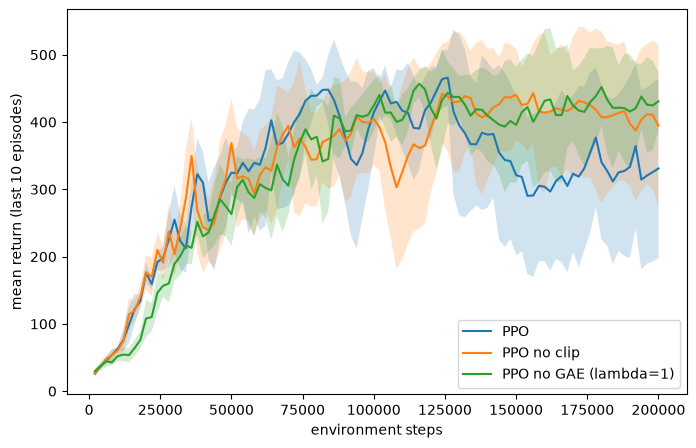

In [6]:
all_runs = {"PPO": run_seeds(),
            "PPO no clip": run_seeds({"clip_coef": 1e9}),
            "PPO no GAE (lambda=1)": run_seeds({"gae_lambda": 1.0})}
results = {name: summarize(runs, name) for name, runs in all_runs.items()}
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plot_curves(all_runs)

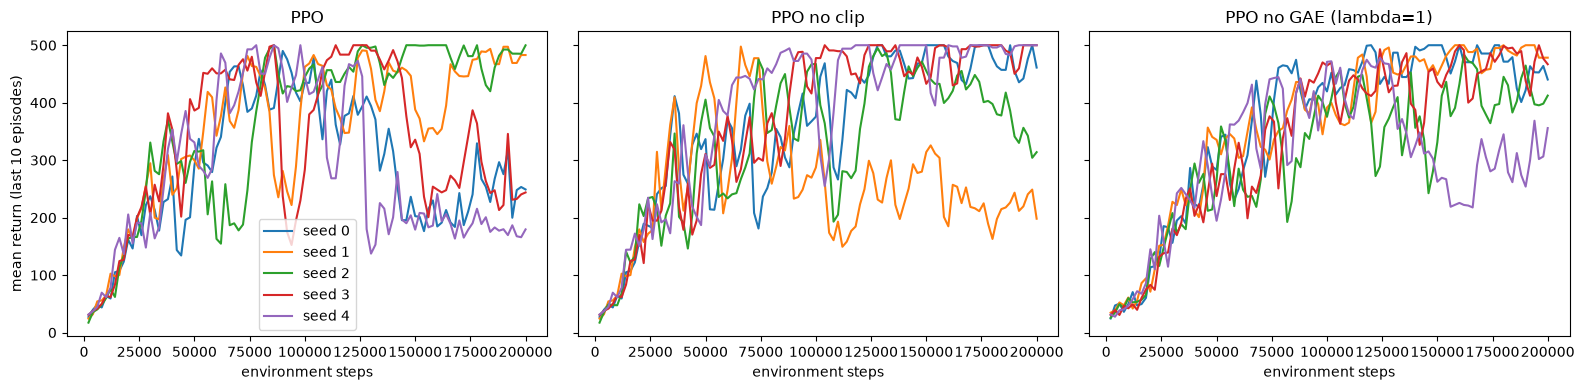

PPO                      seed 0: first >=475 at   90000, min after  176.5, fraction of later points >= 475: 0.05, final curve value  249.0
PPO                      seed 1: first >=475 at   74000, min after  221.9, fraction of later points >= 475: 0.20, final curve value  482.9
PPO                      seed 2: first >=475 at   82000, min after  415.2, fraction of later points >= 475: 0.53, final curve value  499.8
PPO                      seed 3: first >=475 at   72000, min after  152.4, fraction of later points >= 475: 0.26, final curve value  243.8
PPO                      seed 4: first >=475 at   62000, min after  137.4, fraction of later points >= 475: 0.11, final curve value  179.5
PPO no clip              seed 0: first >=475 at  126000, min after  432.3, fraction of later points >= 475: 0.55, final curve value  461.1
PPO no clip              seed 1: first >=475 at   50000, min after  149.3, fraction of later points >= 475: 0.05, final curve value  198.1
PPO no clip              se

In [7]:
# Per-seed learning curves (to see whether each run keeps the maximum return)
fig, axes = plt.subplots(1, len(all_runs), figsize=(16, 4), sharey=True)
for ax, (name, runs) in zip(axes, all_runs.items()):
    for r in runs:
        g, c = learning_curve(r["episodes"])
        ax.plot(g, c, label=f"seed {r['seed']}")
    ax.set_title(name); ax.set_xlabel("environment steps")
axes[0].set_ylabel("mean return (last 10 episodes)"); axes[0].legend(); plt.tight_layout(); plt.show()

# Drops after first reaching 475: min of the curve after the first time it is >= 475
for name, runs in all_runs.items():
    for r in runs:
        g, c = learning_curve(r["episodes"])
        hit = np.where(c >= 475)[0]
        if len(hit):
            after = c[hit[0]:]
            print(f"{name:<24} seed {r['seed']}: first >=475 at {g[hit[0]]:7.0f}, min after {after.min():6.1f}, "
                  f"fraction of later points >= 475: {(after >= 475).mean():.2f}, final curve value {c[-1]:6.1f}")
        else:
            print(f"{name:<24} seed {r['seed']}: never reached 475, max {c.max():6.1f}, final {c[-1]:6.1f}")

## Results and answers for part (a)

All numbers come from `summarize` and `plot_curves` in `ppo_cartpole.ipynb` (5 seeds, 200,000 environment steps per run).

| Method | auc (mean ± std) | steps_to_475 (mean) | solved runs | final (greedy, mean ± std) | time / run |
|---|---|---|---|---|---|
| PPO (default) | 323.3 ± 37.3 | 68,270 | 5/5 | 409.1 ± 108.5 | 13.9 s |
| PPO without clipping (`clip_coef = 1e9`) | 341.1 ± 47.3 | 81,654 | 5/5 | 464.7 ± 61.5 | 16.4 s |
| PPO without GAE (`gae_lambda = 1.0`) | 337.0 ± 25.7 | 119,546 | 5/5 | 496.0 ± 5.9 | 19.4 s |

Diagnostics from an instrumented copy of `ppo_update` (seeds 0 and 1; not part of the notebook):

| Method | fraction of samples with \|r − 1\| > 0.2 | max \|r − 1\| | std of raw advantages | mean value loss |
|---|---|---|---|---|
| PPO | 0.000–0.001 | 0.60–0.64 | 5.8–9.1 | 47–51 |
| PPO without clipping | 0.000–0.002 | 0.71–0.80 | 6.1–10.3 | 47–57 |
| PPO without GAE | 0.000–0.001 | 0.32–0.58 | 15.3–17.0 | 276–280 |

## (i) How does the clipping change learning? Why?

In these runs, removing the clipping changes almost nothing. The differences in auc (323 vs. 341) and in
steps_to_475 (68k vs. 82k) are smaller than the spread between seeds (std ≈ 40), and both versions solve 5/5 runs.

The reason is that the clipping is almost never active with the default settings. With lr = 2.5e-4 (annealed to 0),
only 4 epochs on each rollout, and gradient-norm clipping at 0.5, the new policy stays close to the old one:
fewer than 0.2% of the samples have a probability ratio outside [0.8, 1.2], with or without the clip. When the ratio
stays inside the trust region, the clipped and the unclipped objectives (and their gradients) are the same. Without
clipping, the ratios still move a little further (max |r − 1| of 0.71–0.80 instead of 0.60–0.64), and the
no-clip curves vary more between seeds: one seed collapsed to about 200 and stayed there. So the clip is a safety
mechanism that limits rare large updates; it does not speed up learning. It matters more with larger learning rates,
more update epochs or larger minibatches, where the policy can move far from the policy that collected the data.

## (ii) How does GAE change learning? (bias and variance)

GAE with λ = 0.95 learns about 1.75× faster at the start: it reaches a mean return of 475 after 68k steps,
compared with 120k steps for λ = 1. The λ = 1 curve is visibly lower for the first 50k steps.

* **Variance.** With λ = 1, the advantage is (almost) the Monte Carlo return minus V(s). It sums the noise of every
  future reward and action until the episode ends, or until the end of the 128-step rollout, where it bootstraps
  once. The raw advantages of λ = 1 have a standard deviation 2–3× larger (15–17 vs. 6–9), and the value loss is
  about 5× larger (≈ 278 vs. ≈ 50). Noisier advantages give noisier policy gradients, so learning is slower.
* **Bias.** GAE with λ < 1 weights short TD errors more, so it uses the critic V more. This lowers the variance,
  but it adds bias when V is wrong. The critic is wrong early in training, and also later, for a specific reason: the
  starter treats the time limit at 500 steps (truncation) as a terminal state, but the observation does not contain
  the time. Thus V cannot predict a "terminal" value of 0 near step 500, which biases the TD targets. λ = 1 depends
  less on V, so it has less bias.

In our runs, the variance reduction of GAE wins early: faster learning and a 5/5 solve rate at about 68k steps. Later,
the lower bias of λ = 1 seems to help stability: its greedy final return is 496 ± 6, compared with 409 ± 108, and its
learning curve dips less after it reaches its maximum. This is the usual bias–variance trade-off that λ controls.

## (iii) Does PPO keep the maximum return after it gets there?

No, not reliably. All 5 default PPO seeds reach a mean return of ≥ 475 (between 62k and 90k steps). But afterwards,
the per-seed curves often fall back:

| Seed | first ≥ 475 at | minimum after | fraction of later points ≥ 475 | value at 200k |
|---|---|---|---|---|
| 0 | 90k | 177 | 0.05 | 249 |
| 1 | 74k | 222 | 0.20 | 483 |
| 2 | 82k | 415 | 0.53 | 500 |
| 3 | 72k | 152 | 0.26 | 244 |
| 4 | 62k | 137 | 0.11 | 180 |

Seeds 0, 3 and 4 collapse to about 200 after about 125k steps and do not recover. Thus the mean curve falls from
about 440 to about 330, and the final greedy return has a large spread (214 to 500). Only seed 2 stays near 500.
The ablations show the same effect, but weaker: without clipping, 2 of 5 seeds end low; without GAE, the dips
are smaller.

Reasons:

* **No signal at the maximum.** When almost all episodes reach 500, the true advantages are close to 0. With
  `norm_adv = True`, each minibatch is normalized to unit variance anyway, so the update follows noise (and the
  wrong values near truncation, see (ii)) with the full step size, and it can move a good policy away from the optimum.
* **Truncation as termination.** The value targets near step 500 are wrong, so the advantages near the end of an
  episode are biased.
* **Learning-rate annealing** decreases the learning rate linearly to 0. This reduces the size of the late updates
  and limits the damage (the collapses occur between 100k and 150k, when the learning rate is still 25–50% of the
  start), but it cannot undo a collapse: at the end, the learning rate is too small to recover, so collapsed seeds
  stay at about 200.


# Bonus Research Question 2: your method

Write your method as a copy of `train_ppo` (and of the other functions that you change).
Use `run_seeds(train_fn=my_train_ppo)` and `summarize` for the results.

In [8]:
def my_train_ppo(seed, cfg=None, verbose=False, options=None):
    # TODO: your method
    raise NotImplementedError